<a href="https://colab.research.google.com/github/PiaokertheKTH/cb2330-portfolio/blob/main/project_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project card
## The paper

Schwanhäusser et al. (2011), *Global quantification of mammalian gene expression control*, Nature.

## The data object
Heavy/light (H/L) protein ratios measured at 1.5, 4.5 and 13.5 h after the start of heavy SILAC pulse labeling.

H: newly synthesized heavy-labelled protein; L: pre-existing light protein.

Rrm2: `H/L = (0.24, 1.26, 12.8)`  
Hist1h1c: `H/L = (0.05, 0.19, 0.63)`


## The random variable chosen

Degradation of one pre-existing light protein during one simulation interval.

$$
X \sim \mathrm{Bernoulli}(p_{\mathrm{deg}})
$$

$$
p_{\mathrm{deg}} = 1-e^{-K_{dp}\Delta t}
$$


## What the paper does

Pulse-SILAC measurement of protein turnover; protein half-life estimated from the increase of

$$
\ln(1+H/L)
$$

with time.

Published half-lives: Rrm2 = 4.52 h; Hist1h1c = 62.07 h.


## The generative model proposed

Protein degradation:

$$
K_{dp}=\frac{\ln 2}{T_{1/2}}
$$

Cell-population growth:

$$
K_{\mathrm{dil}}=\frac{\ln 2}{T_{\mathrm{cell}}}
$$

Stochastic degradation of light proteins + asynchronous cell division → simulated H/L ratios at the three sampling times.


## Parameters and assumptions

Main parameter:

$$
\theta=\log_{10}(T_{1/2})
$$

- constant protein degradation rate
- fixed cell doubling time: $T_{\mathrm{cell}}=27.5$ h
- simulation step: $\Delta t=0.5$ h
- asynchronous exponentially growing cells
- 10,000 initial light proteins in 1,000 cells
- newly produced/replaced protein counted as heavy

Prior:

$$
\theta \sim N(\mu_{\mathrm{prior}},\sigma_{\mathrm{prior}}^2)
$$

Rrm2: $\mu=\log_{10}(4.03)$, $\sigma=0.04$  
Hist1h1c: $\mu=\log_{10}(52.31)$, $\sigma=0.06$

Prior widths currently provisional.


## The forward simulation

Input a known $T_{1/2}$ → simulate degradation and cell growth → obtain three synthetic H/L measurements.

Regression summary:

$$
s=\frac{\sum t_i y_i}{\sum t_i^2},
\qquad
y_i=\ln(1+H/L)
$$

Recover degradation rate and half-life:

$$
K_{dp}=s-K_{\mathrm{dil}}
$$

$$
T_{1/2}=\frac{\ln2}{K_{dp}}
$$


## The parameterization / fitting

Observed summary statistic:

$$
K_{dp,\mathrm{obs}}
=
s_{\mathrm{obs}}-\frac{\ln2}{T_{\mathrm{cell}}}
$$

Data-derived reference:

$$
T_{\mathrm{REF}}
=
\frac{\ln2}{K_{dp,\mathrm{obs}}}
$$

ABC tolerance from repeated simulations at $T_{\mathrm{REF}}$.

ABC-MCMC distance:

$$
d=
|K_{dp,\mathrm{sim}}-K_{dp,\mathrm{obs}}|
$$

Accept candidate when $d\leq\varepsilon$, followed by the prior-ratio test.


## What the model adds to the paper

Mechanistic stochastic simulation of the SILAC process.

Posterior distribution of protein half-life instead of only one point estimate; explicit uncertainty and forward recovery test.


## Model limitations / how it breaks

- only three sampling time points
- constant degradation rate
- fixed cell-cycle length
- no peptide-specific or mass-spectrometry measurement error
- simplified heavy-protein production
- regression forced through the origin
- Rrm2 displayed H/L values do not reproduce the published 4.52 h exactly
- prior SD currently based on a provisional choice

In [ ]:
#Considering cell division
import math
import matplotlib.pyplot as plt
import numpy as np
# experimantal parameters
T_cell_dup = 27.5 #hour, given

# Choose one protein
PROTEIN = "Rrm2"

if PROTEIN == "Rrm2":
    HL_OBS = (0.24, 1.26, 12.8)
    PUBLISHED_T_HALF = 4.52
elif PROTEIN == "Hist1h1c":
    HL_OBS = (0.05, 0.19, 0.63)
    PUBLISHED_T_HALF = 62.07
else:
    raise ValueError(f"Unknown protein: {PROTEIN}")

T_half = PUBLISHED_T_HALF # hour, given


# self-defined parameters
N = 10000   # number of L0
N_cell = 1000  # number of cells
time_sep = 0.5 # simulate per 30 minutes
seed = 42



# Sampled time points
t_set = [1.5,4.5,13.5]
t_sample = np.arange(time_sep,t_set[-1]+time_sep,0.5)
t_set_index = [int(time/time_sep)-1 for time in t_set]


In [ ]:
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32


def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m

def mean(values):
    """The sample mean, the sum over the list divided by its length."""
    total = 0.0
    for v in values:
        total = total + v
    return total / len(values)

def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out, state

def std(values):
  """The sample standard deviation, the root of the average squared deviation from the mean."""
  m = mean(values)
  total = 0.0
  for v in values:
      total = total + (v - m) ** 2
  return (total / len(values)) ** 0.5

In [ ]:
def simulate(T_half, T_cell_dup, state):
    K_dp = math.log(2) / T_half  # rate per hour # Deduced protein dilimination rate
    cell_growth_rate = np.log(2) / T_cell_dup

    # protein degradation probability
    p = 1 - math.exp(-K_dp*time_sep)
    #print(f'p:{p}')


    # set seed
    np.random.seed(state)

    u = np.random.random(N_cell)
    cell_ages = -np.log(1 - u / 2) / cell_growth_rate
    #print(f'cell_ages:{cell_ages}')


    # original Light proteins number in each cell
    protein_counts_in_cells = np.random.multinomial(N,[1/N_cell] * N_cell)


    # calcualate total protein counts for every time points
    total_counts = [0] * len(t_sample)


    for i in range(len(t_sample)):
      total_counts[i] += int(sum([protein_counts_in_cells[j]*2**((cell_ages[j] + t_sample[i]) // T_cell_dup) for j in range(N_cell)]))

    #print(f'total_counts{total_counts}')
    L_counts = [N] * len(t_sample)


    # Simulation without formula

    L_rs,state = uniforms(N * len(t_sample), state)


    for i in range(N):
      for t_id in range(len(t_sample)):
        if L_rs[i*len(t_sample)+t_id] < p:
          # H_counts[t_id:] = [x + 1 for x in H_counts[t_id:]]
          L_counts[t_id:] = [x - 1 for x in L_counts[t_id:]]
          break

    H_counts = [total_counts[i] - L_counts[i] for i in range(len(t_sample))]
    #print(f'H_counts:{H_counts}')

    H_sample = [H_counts[i] for i in t_set_index]
    L_sample = [L_counts[i] for i in t_set_index]
    HL_ratio = np.array(H_sample) / np.array(L_sample)


    #print(f'HL_ratio:{HL_ratio}')
    ln_HL_ratio = np.log(1 + np.array(H_sample) / np.array(L_sample))


    return ln_HL_ratio, state


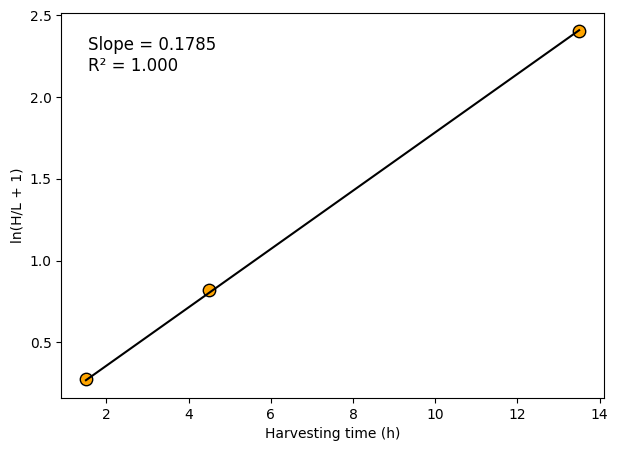

data_Kdp:0.1532509554651404, data_t_half:4.522955034480119


In [ ]:

#### DRAW
state = seed
ln_HL_ratio, state = simulate(T_half, T_cell_dup, state)

x = np.array(t_set)
y = np.array(ln_HL_ratio)

# Linear regression: y = slope * x + intercept
t_obs = np.array([1.5, 4.5, 13.5])

def get_slope(y):
    return np.sum(t_obs * y) / np.sum(t_obs ** 2)

x = t_obs
y = np.array(ln_HL_ratio)

slope = get_slope(y)
intercept = 0.0
y_pred = slope * x

# R-squared
r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)

# Draw
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="orange", edgecolor="black", s=80)
plt.plot(x, y_pred, color="black")

plt.xlabel("Harvesting time (h)")
plt.ylabel("ln(H/L + 1)")

plt.text(
    0.05, 0.85,
    f"Slope = {slope:.4f}\nR² = {r2:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12
)

plt.show()


data_Kdp = slope - math.log(2) / T_cell_dup
data_t_half = math.log(2) / data_Kdp
print(f'data_Kdp:{data_Kdp}, data_t_half:{data_t_half}')




In [ ]:
# Prior
LOG_T_MIN = np.log10(0.5)
LOG_T_MAX = np.log10(200)

if PROTEIN == "Rrm2":
    PRIOR_MEAN = np.log10(4.03)      # independent replicate
    PRIOR_SD = 0.04
elif PROTEIN == "Hist1h1c":
    PRIOR_MEAN = np.log10(52.31)     # independent replicate
    PRIOR_SD = 0.06

def prior(log10_t_half):
    if LOG_T_MIN <= log10_t_half <= LOG_T_MAX:
        return math.exp(
            -(log10_t_half - PRIOR_MEAN) ** 2 / (2 * PRIOR_SD ** 2)
        ) / (PRIOR_SD * math.sqrt(2 * math.pi))
    return 0.0

In [ ]:
paper_proteins = {
    "Rrm2": {
        "HL": (0.24, 1.26, 12.8),
        "published_T_half": 4.52
    },
    "Hist1h1c": {
        "HL": (0.05, 0.19, 0.63),
        "published_T_half": 62.07
    }
}

print("\nPaper data")

for name, values in paper_proteins.items():
    y_paper = np.array([math.log(x + 1) for x in values["HL"]])
    slope_paper = get_slope(y_paper)
    Kdp_paper = get_Kdp(y_paper)
    T_half_paper_data = math.log(2) / Kdp_paper

    print(f"\n{name}")
    print(f"slope from displayed H/L = {slope_paper:.5f} h^-1")
    print(f"Kdp = {Kdp_paper:.5f} h^-1")
    print(f"T_half from displayed H/L = {T_half_paper_data:.2f} h")
    print(f"published T_half = {values['published_T_half']:.2f} h")


Paper data

Rrm2
slope from displayed H/L = 0.19255 h^-1
Kdp = 0.16735 h^-1
T_half from displayed H/L = 4.14 h
published T_half = 4.52 h

Hist1h1c
slope from displayed H/L = 0.03639 h^-1
Kdp = 0.01119 h^-1
T_half from displayed H/L = 61.95 h
published T_half = 62.07 h


In [ ]:

t_obs = np.array(t_set)

observed = [math.log(x + 1) for x in HL_OBS]

y_obs = np.array(observed)

def get_Kdp(y):
    return get_slope(y) - math.log(2) / T_cell_dup
Kdp_obs = get_Kdp(y_obs)


data_t_half = math.log(2) / Kdp_obs

T_REF = data_t_half

REPEATS = 500
Kdp_results = []

state = seed

for r in range(REPEATS):
    y_sim, state = simulate(T_REF,T_cell_dup,state)
    Kdp_sim = get_Kdp(y_sim)
    Kdp_results.append(Kdp_sim)

Kdp_results = np.array(Kdp_results)
Kdp_center = np.mean(Kdp_results)
Kdp_sigma = np.std(Kdp_results, ddof=1)



EPSILON = Kdp_sigma


print("\nCalibration")
print("Kdp center =", Kdp_center)
print("Kdp sigma  =", Kdp_sigma)



d_obs = abs(Kdp_obs - Kdp_center)

print("\nObserved vs reference simulation")
print("observed Kdp   =", Kdp_obs)
print("center Kdp     =", Kdp_center)
print("distance       =", d_obs)
print("epsilon        =", EPSILON)


Calibration
Kdp center = 0.16728077614027026
Kdp sigma  = 0.0023455542369387188

Observed vs reference simulation
observed Kdp   = 0.16734573331984323
center Kdp     = 0.16728077614027026
distance       = 6.495717957297198e-05
epsilon        = 0.0023455542369387188


In [ ]:

growth_rate = math.log(2) / T_cell_dup

data_Kdp = Kdp_obs
data_t_half = math.log(2) / data_Kdp

print("\nAnalytical estimate")
print("data_Kdp =", data_Kdp)
print("data_t_half =", data_t_half)



Analytical estimate
data_Kdp = 0.16734573331984323
data_t_half = 4.142006890818975


In [ ]:

STEPS = 5000
DELTA = 0.04
START = np.log10(data_t_half)

def abc_mcmc(steps, epsilon, delta, start, state):
    theta = start
    chain = [0.0] * steps
    accepted = 0
    turned_away = 0

    for i in range(steps):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        r = state / M_LCG
        proposal = theta + (2 * r - 1) * delta

        y_sim, state = simulate(10 ** proposal, T_cell_dup, state)
        Kdp_sim = get_Kdp(y_sim)
        distance = abs(Kdp_sim - Kdp_obs)

        state = lcg(state, A_LCG, C_LCG, M_LCG)
        u = state / M_LCG
        alpha = min(1.0, prior(proposal) / prior(theta)) if distance <= epsilon else 0

        if u < alpha:
            theta = proposal
            accepted += 1
        else:
            if distance <= epsilon:
                turned_away += 1

        chain[i] = theta

    return chain, accepted, turned_away, state


chain, accepted, turned_away, state = abc_mcmc(STEPS, EPSILON, DELTA, START, 2330008)

print(f"steps {STEPS}   accepted {accepted}   acceptance rate {accepted / STEPS:.1%}")
print(f"rejected for landing outside the tolerance: {STEPS - accepted - turned_away}")
print(f"rejected by the prior ratio alone:          {turned_away}")

T_half_chain = 10 ** np.array(chain)
burn_in = int(0.2 * STEPS)
posterior_T_half = T_half_chain[burn_in:]

print(f"posterior mean T_half:   {np.mean(posterior_T_half):.3f} h")
print(f"posterior median T_half: {np.median(posterior_T_half):.3f} h")
print(
    f"95% credible interval: "
    f"{np.quantile(posterior_T_half, 0.025):.3f} - "
    f"{np.quantile(posterior_T_half, 0.975):.3f} h"
)


steps 5000   accepted 710   acceptance rate 14.2%
rejected for landing outside the tolerance: 4290
rejected by the prior ratio alone:          0
posterior mean T_half:   4.143 h
posterior median T_half: 4.136 h
95% credible interval: 4.026 - 4.290 h


In [ ]:

BURN = int(0.2 * STEPS)
posterior_sample = chain[BURN:]

centre = mean(posterior_sample)
width = std(posterior_sample)
lower = np.quantile(posterior_sample, 0.025)
upper = np.quantile(posterior_sample, 0.975)



THRESHOLD = np.log10(PUBLISHED_T_HALF)

above = 0
for t in posterior_sample:
    if t > THRESHOLD:
        above += 1

print(f"posterior mean log10(T_half)  {centre:.3f}, geometric mean T_half {10 ** centre:.3f} h")
print(f"posterior sd    {width:.3f} in log10")
print(f"95% posterior interval  {lower:.3f} to {upper:.3f} in log10")
print(f"95% posterior interval  {10 ** lower:.3f} to {10 ** upper:.3f} h")
print(f"P(T_half > {PUBLISHED_T_HALF:.2f} h) = {above / len(posterior_sample):.3f}")


posterior mean log10(T_half)  1.797, geometric mean T_half 62.648 h
posterior sd    0.046 in log10
95% posterior interval  1.723 to 1.877 in log10
95% posterior interval  52.861 to 75.384 h


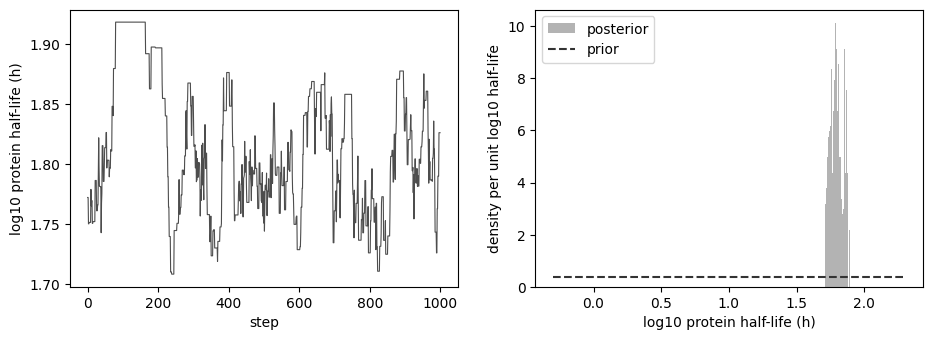

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

ax1.plot(range(STEPS), chain, color="0.3", linewidth=0.8)
ax1.set_xlabel("step")
ax1.set_ylabel("log10 protein half-life (h)")

ax2.hist(posterior_sample, bins=30, density=True, color="0.7", label="posterior")

grid = [0.0] * 200
prior_curve = [0.0] * 200

for j in range(200):
    grid[j] = LOG_T_MIN + j * ((LOG_T_MAX - LOG_T_MIN) / 199)
    prior_curve[j] = prior(grid[j])

ax2.plot(grid, prior_curve, color="0.2", linestyle="--", label="prior")
ax2.set_xlabel("log10 protein half-life (h)")
ax2.set_ylabel("density per unit log10 half-life")
ax2.legend()

plt.show()


In [ ]:
PUBLISHED_LOG10_T = np.log10(PUBLISHED_T_HALF)

print(f"published experimental half-life: {PUBLISHED_LOG10_T:.3f} in log10 "
      f"({PUBLISHED_T_HALF:.2f} h)")
print(f"95% posterior interval:           "
      f"{np.quantile(posterior_T_half, 0.025):.3f} to "
      f"{np.quantile(posterior_T_half, 0.975):.3f} h")

if np.quantile(posterior_T_half, 0.025) <= PUBLISHED_T_HALF <= np.quantile(posterior_T_half, 0.975):
    print("the posterior interval covers the published experimental estimate")
else:
    print("the posterior interval does not cover the published experimental estimate")


published experimental half-life: 1.793 in log10 (62.07 h)
95% posterior interval:           52.861 to 75.384 h
the posterior interval covers the published experimental estimate
